In [ ]:
###### This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk("./"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# 1. Frame the problem
Using the customer description, Define the problem your trying to solve in your own words (remember this is not technial but must be specific so the customer understands the project

The problem is figuring out a way to make a machine learning model play Tetris for a long time.

# 2. Get the Data 
Define how you recieved the data (provided, gathered..)

In [1]:
import sys

print(sys.version)
print(sys.executable)

# !{sys.executable} -m venv ~/tetris_env
# !~/tetris_env/bin/python -m pip install --upgrade pip
# !~/tetris_env/bin/python -m pip install ipykernel
# !~/tetris_env/bin/python -m ipykernel install --user --name=tetris_env --display-name="Python (Tetris)"
# !git clone https://gitlab.com/yukiman/tetris_a.git
# %cd tetris_a
# !ls -la
# !~/tetris_env/bin/python -m pip install -r requirements.txt
# !{sys.executable} -m pip install -r requirements.txt

3.12.6 | packaged by conda-forge | (main, Sep 22 2024, 14:16:49) [GCC 13.3.0]
/home/jupyter-250661/tetris_env/bin/python


In [3]:
!jupyter kernelspec list

Available kernels:
  tetris_env    /home/jupyter-250661/.local/share/jupyter/kernels/tetris_env
  python3       /opt/tljh/user/share/jupyter/kernels/python3


# 3. Explore the Data
Gain insights into the data you have from step 2, making sure to identify any bias

A virtual environment for the Tetris game was created, in addition to a new kernel, Python (Tetris).

# 4.Prepare the Data


Apply any data transformations and explain what and why


In [3]:
import numpy as np
import random
import copy
import sys
#!{sys.executable} -m pip install matplotlib
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim
from board import Board
from piece import Piece, BODIES

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

board = Board()
piece = Piece()

print("Board dimensions:", board.width, "x", board.height)
print("Piece body:", piece.body)
print("Piece skirt:", piece.skirt)

PyTorch: 2.15.0+cu132
CUDA available: False
Using device: cpu
Board dimensions: 10 x 20
Piece body: ((0, 0), (0, 1), (0, 2), (1, 0))
Piece skirt: [0, 0]


/home/jupyter-250661/tetris_env/lib/python3.12/site-packages/torch/cuda/__init__.py:241: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
%cd src/

/home/jupyter-250661/Project_6/tetris_a/src


# 5. Model the data
Using selected ML models, experment with your choices and describe your findings. Finish by selecting a Model to continue with


In [19]:
def get_state(board, piece):

    board_state = np.array(board.board, dtype=np.float32).flatten()
    piece_state = np.zeros((4, 4), dtype=np.float32)

    for x, y in piece.body:
        piece_state[y, x] = 1

    heights = np.array(board.heights, dtype=np.float32)
    heights = heights / board.height
    holes = np.zeros(board.width, dtype=np.float32)

    for x in range(board.width):
        for y in range(board.heights[x]):
            if not board.board[y][x]:
                holes[x] += 1

    holes = holes / board.height

    aggregate_height, total_holes, bumpiness = (get_board_metrics(board))

    extra_features = np.array([
        aggregate_height / (board.width * board.height),
        total_holes / (board.width * board.height),
        bumpiness / (board.width * board.height)
    ], dtype=np.float32)

    state = np.concatenate([
        board_state,
        piece_state.flatten(),
        heights,
        holes,
        extra_features
    ])

    return state

def get_board_metrics(board):

    heights = board.heights
    aggregate_height = sum(heights)
    holes = 0

    for x in range(board.width):
        for y in range(heights[x]):
            if not board.board[y][x]:
                holes += 1

    bumpiness = sum(abs(heights[x] - heights[x + 1]) for x in range(board.width - 1))

    return aggregate_height, holes, bumpiness

def greedy_board_cost(board, x=None, y=None, piece=None):

    board_copy = deepcopy(board.board)

    if piece is not None:
        for px, py in piece.body:
            board_copy[y + py][x + px] = True

    holes = 0
    max_height = 0
    num_cleared = 0

    for i in range(len(board_copy)):

        if all(board_copy[i]):
            num_cleared += 1

        for j in range(len(board_copy[0])):

            if board_copy[i][j]:
                max_height = max(max_height, i)
                continue

            if any(board_copy[k][j] for k in range(i + 1, len(board_copy))):
                holes += 1

    agg_height = 0
    heights = []

    for col in range(len(board_copy[0])):

        column_height = 0

        for row in range(len(board_copy)):
            if board_copy[row][col]:
                column_height = row

        agg_height += column_height
        heights.append(column_height)

    bumpiness = sum(
        abs(heights[i] - heights[i + 1])
        for i in range(len(heights) - 1)
    )

    return (
        0.5 * agg_height
        + 0.35 * holes
        + 0.18 * bumpiness
        - 0.76 * num_cleared
    )

class TetrisEnv:

    def __init__(self):

        self.width = 10
        self.height = 20
        self.board = None
        self.piece = None
        self.pieces_placed = 0
        self.rows_cleared = 0

    def reset(self):

        self.board = Board()
        self.piece = Piece()
        self.pieces_placed = 0
        self.rows_cleared = 0

        return get_state(self.board, self.piece)

    def get_rotations(self):

        rotations = []
        current = self.piece

        for _ in range(4):

            rotations.append(current)
            current = current.get_next_rotation()

        return rotations

    def valid_actions(self):

        valid = np.zeros(40, dtype=bool)
        rotations = self.get_rotations()

        for r, piece in enumerate(rotations):
            for x in range(self.width):
                if x + len(piece.skirt) > self.width:
                    continue

                y = self.board.drop_height(piece, x)

                if y < 0:
                    continue

                if y + max(pos[1] for pos in piece.body) >= self.board.height + 4:
                    continue

                collision = False

                for px, py in piece.body:
                    bx = x + px
                    by = y + py

                    if self.board.board[by][bx]:
                        collision = True
                        break

                if not collision:
                    action = r * 10 + x
                    valid[action] = True

        return valid

    def step(self, action):
        valid = self.valid_actions()
        if action < 0 or action >= 40 or not valid[action]:
            raise ValueError(f"Invalid action: {action}")
        
        rotation = action // 10
        x = action % 10
        
        piece = self.get_rotations()[rotation]

        y = self.board.drop_height(piece, x)

        result = self.board.place(x, y, piece)

        if isinstance(result, Exception):
            raise ValueError("Invalid Tetris placement")

        self.pieces_placed += 1

        lines = self.board.clear_rows()
        self.rows_cleared += lines

        reward = 1.0 + (lines ** 2) * 10.0
        
        done = self.board.top_filled()
        if done:
            reward = -10.0

        self.piece = Piece()

        next_state = get_state(self.board, self.piece)

        return next_state, reward, done


In [20]:
class DQN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(279, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 40)
        )

    def forward(self, state):
        return self.network(state)

In [21]:
class DQNAgent:

    def __init__(self):
        self.policy_net = DQN().to(device)
        self.target_net = DQN().to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=0.0001)
        self.memory = deque(maxlen=100000)
        self.batch_size = 64
        self.gamma = 0.99
        self.epsilon = 1.0
        self.epsilon_min = 0.001
        self.epsilon_decay = 0.99
        self.target_update = 500
        self.steps = 0

    def select_action(self, state, valid_actions):

        possible_actions = np.flatnonzero(valid_actions)
        if len(possible_actions) == 0:
            raise ValueError("No valid actions available")

        if random.random() < self.epsilon:
            return int(random.choice(possible_actions))

        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

        with torch.no_grad():
            q_values = self.policy_net(state_tensor)
            mask = torch.tensor(valid_actions, dtype=torch.bool, device=device)
            q_values[0][~mask] = -float("inf")

            return int(q_values.argmax(dim=1).item())

    def remember(self, state, action, reward, next_state, done, next_mask):

        self.memory.append((
            np.array(state, dtype=np.float32),
            action,
            reward,
            np.array(next_state, dtype=np.float32),
            done,
            np.array(next_mask, dtype=bool)
        ))
        
    def train_step(self):
        if len(self.memory) < self.batch_size:
            return None
            
        batch = random.sample(self.memory, self.batch_size)
        states, actions, rewards, next_states, dones, masks = zip(*batch)
        states = torch.tensor(np.array(states), dtype=torch.float32, device=device)
        actions = torch.tensor(actions, dtype=torch.long, device=device).unsqueeze(1)
        rewards = torch.tensor(rewards, dtype=torch.float32, device=device)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32, device=device)
        dones = torch.tensor(dones, dtype=torch.float32, device=device)
        masks = torch.tensor(np.array(masks), dtype=torch.bool, device=device)

        current_q = self.policy_net(states).gather(1, actions).squeeze(1)
        with torch.no_grad():
            next_policy_q = self.policy_net(next_states)
            next_policy_q = next_policy_q.masked_fill(~masks, float("-inf"))
            next_actions = next_policy_q.argmax(dim=1, keepdim=True)
            next_target_q = self.target_net(next_states)
            max_next_q = next_target_q.gather(1, next_actions).squeeze(1)
            no_valid_actions = ~masks.any(dim=1)
            max_next_q = torch.where(dones.bool() | no_valid_actions, torch.zeros_like(max_next_q), max_next_q)
            target_q = rewards + (self.gamma * max_next_q * (1 - dones))
            
        loss = nn.functional.smooth_l1_loss(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10)
        self.optimizer.step()
        self.steps += 1
        
        if self.steps % self.target_update == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
            
        return loss.item()


    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

New replay memory: 0
New training steps: 0
Initial epsilon: 1.0
Episode: 1/2000 | Pieces: 23 | Lines: 0 | Reward: 12.00 | Epsilon: 0.990
Episode: 2/2000 | Pieces: 20 | Lines: 0 | Reward: 9.00 | Epsilon: 0.980
Episode: 3/2000 | Pieces: 23 | Lines: 0 | Reward: 12.00 | Epsilon: 0.970
Episode: 4/2000 | Pieces: 17 | Lines: 0 | Reward: 6.00 | Epsilon: 0.961
Episode: 5/2000 | Pieces: 24 | Lines: 0 | Reward: 13.00 | Epsilon: 0.951
Episode: 6/2000 | Pieces: 21 | Lines: 0 | Reward: 10.00 | Epsilon: 0.941
Episode: 7/2000 | Pieces: 26 | Lines: 0 | Reward: 15.00 | Epsilon: 0.932
Episode: 8/2000 | Pieces: 17 | Lines: 0 | Reward: 6.00 | Epsilon: 0.923
Episode: 9/2000 | Pieces: 19 | Lines: 0 | Reward: 8.00 | Epsilon: 0.914
Episode: 10/2000 | Pieces: 19 | Lines: 0 | Reward: 8.00 | Epsilon: 0.904
Episode: 11/2000 | Pieces: 18 | Lines: 0 | Reward: 7.00 | Epsilon: 0.895
Episode: 12/2000 | Pieces: 17 | Lines: 0 | Reward: 6.00 | Epsilon: 0.886
Episode: 13/2000 | Pieces: 21 | Lines: 0 | Reward: 10.00 | Epsil

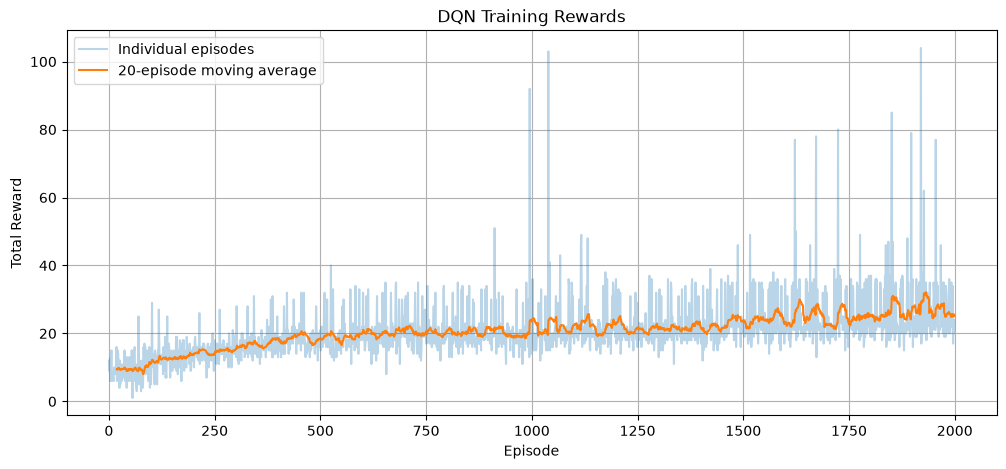

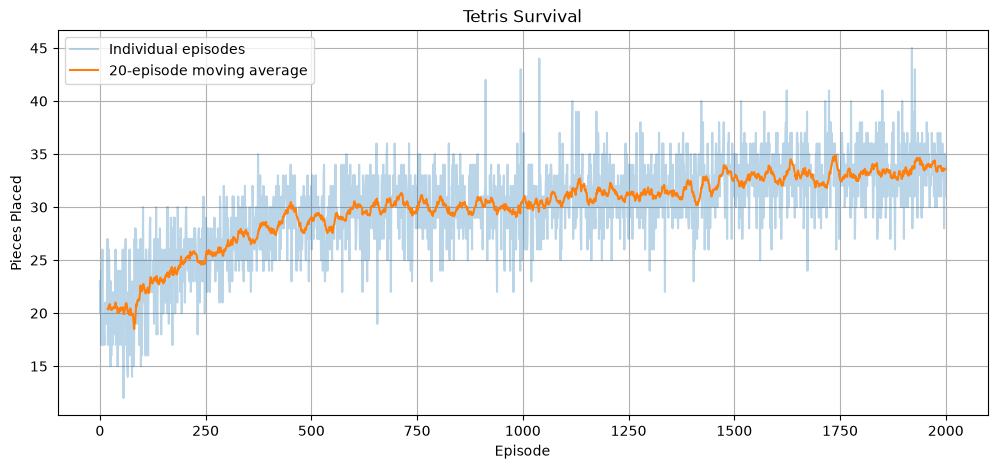

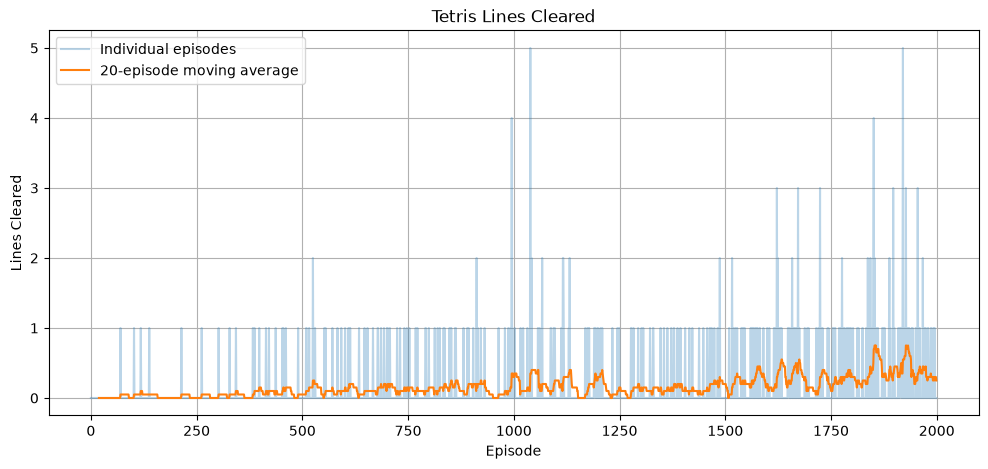

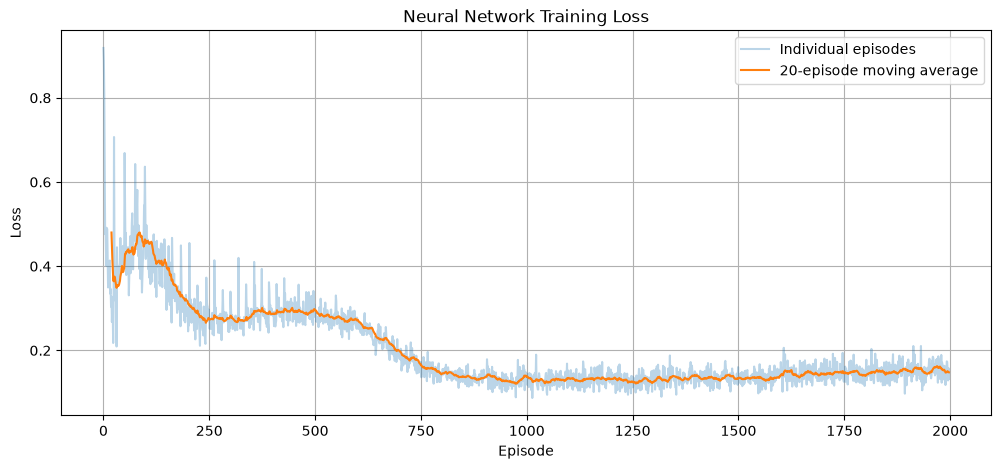

In [22]:
import numpy as np

env = TetrisEnv()
agent = DQNAgent()

print("New replay memory:", len(agent.memory))
print("New training steps:", agent.steps)
print("Initial epsilon:", agent.epsilon)


episodes = 2000
max_pieces = 2000
train_freq = 1

scores = []
pieces_history = []
lines_history = []
loss_history = []

global_step = 0

for episode in range(episodes):

    state = env.reset()
    total_reward = 0
    pieces = 0
    total_loss = []

    for step in range(max_pieces):

        valid_actions = env.valid_actions()

        if not np.any(valid_actions):
            break

        action = agent.select_action(state, valid_actions)

        next_state, reward, done = env.step(action)

        next_mask = (
            np.zeros(40, dtype=bool)
            if done
            else env.valid_actions()
        )

        if not np.any(next_mask):
            done = True

        agent.remember(
            state,
            action,
            reward,
            next_state,
            done,
            next_mask
        )

        global_step += 1

        if global_step % train_freq == 0:
            loss = agent.train_step()

            if loss is not None:
                total_loss.append(loss)

        state = next_state
        total_reward += reward
        pieces += 1

        if done:
            break

    agent.decay_epsilon()

    scores.append(total_reward)
    pieces_history.append(pieces)
    lines_history.append(env.rows_cleared)

    if total_loss:
        loss_history.append(np.mean(total_loss))

    print(f"Episode: {episode + 1}/{episodes} | Pieces: {pieces} | Lines: {env.rows_cleared} | Reward: {total_reward:.2f} | Epsilon: {agent.epsilon:.3f}")


def plot_training(history, title, ylabel):
    plt.figure(figsize=(12, 5))
    plt.plot(history, alpha=0.3, label="Individual episodes")

    if len(history) >= 20:
        moving_avg = np.convolve(history, np.ones(20) / 20, mode="valid")
        plt.plot(range(19, len(history)), moving_avg, label="20-episode moving average")

    plt.title(title)
    plt.xlabel("Episode")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid()
    plt.show()

plot_training(scores, "DQN Training Rewards", "Total Reward")
plot_training(pieces_history, "Tetris Survival", "Pieces Placed")
plot_training(lines_history, "Tetris Lines Cleared", "Lines Cleared")
plot_training(loss_history,"Neural Network Training Loss", "Loss")

##### 6. Fine Tune the Model

With the select model descibe the steps taken to acheve the best rusults possiable 

In [23]:
torch.save(agent.policy_net.state_dict(), "dqn_tetris.pth")
print("model saved")

model saved


# 7. Present
In a customer faceing Document provide summery of finding and detail approach taken



# 8. Launch the Model System
Define your production run code, This should be self susficent and require only your model pramaters 


In [25]:
import sys
sys.path.insert(0, "src")
from game import Game

game = Game("student")
pieces, rows = game.run_no_visual()

print("Pieces placed:", pieces)
print("Rows cleared:", rows)

1 0
2 0
3 0
4 0
5 1
6 1
7 1
8 1
9 1
10 2
11 2
12 2
13 2
14 2
15 2
16 2
17 2
18 2
19 2
20 2
21 3
22 3
23 3
24 3
25 3
26 3
27 3
28 3
29 3
30 3
31 3
32 3
33 3
34 3
35 3
36 3
37 3
38 3
39 3
40 3
41 3
42 3
42 3
Pieces placed: 42
Rows cleared: 3
